In [1]:
import neuron
from neuron import h
import matplotlib.pyplot as plt
from neuron.units import ms, mV
import numpy as np
pth_mod = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/model_db_hay/mod'
figpth = '/Users/katharinaduecker/Documents/projects_brown/hnn_dev/figures/newl5_hay/'
# import os
# os.mkdir(figpth)
from cell_builder_utils import l2_params, _get_dends, _get_pyr_soma, Cell
from iascone_mechs_utils import Mechs, get_iascone_params, Ih_condu_apical, distribute_gbar
from plot_utils import fig_conductances, fig_compartments
from functools import partial
from scipy.signal import find_peaks
from hnn_core.viz import plot_cell_morphology

import pandas as pd

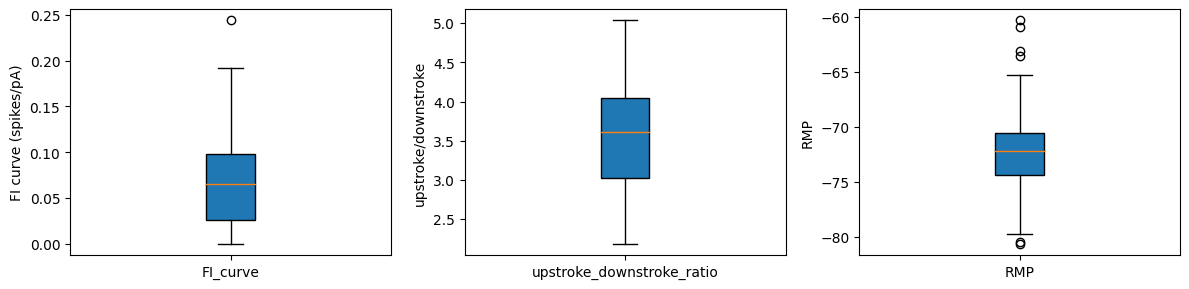

In [2]:
df = pd.read_csv('cell_types_specimen_details.csv')
humanl3 = df[df['structure__layer'] == '3']
#df['etype'].value_counts() # 1 seems to be the E-type cells
humanl3 = humanl3[humanl3['tag__apical'] == 'intact']

humanl3['ef__f_i_curve_slope']

'ef__upstroke_downstroke_ratio_long_square'

'ef__vrest'

fig, ax = plt.subplots(1,3, figsize=(12,3))

ax = ax.ravel()
ax[0].boxplot(humanl3['ef__f_i_curve_slope'], vert=True, patch_artist=True, labels=['FI_curve'])
ax[0].set_ylabel('FI curve (spikes/pA)')

ax[1].boxplot(humanl3['ef__upstroke_downstroke_ratio_long_square'], vert=True, patch_artist=True, labels=['upstroke_downstroke_ratio'])
ax[1].set_ylabel('upstroke/downstroke')

ax[2].boxplot(humanl3['ef__vrest'], vert=True, patch_artist=True, labels=['RMP'])
ax[2].set_ylabel('RMP')

fig.tight_layout()

In [3]:
iascone_model_params = {'soma': {'NaTs2_t': 0.926705*.65, 
                                'SKv3_1': 0.102517,
                                'Nap_Et2': 0,
                                'Ca_HVA': 0.000374,
                                'Ca_LVAst': 0.000778,
                                'SK_E2': 0.099433,
                                'pas': 1.0 / 12000.0,
                                'Ih': 0.000080,
                                'Im': 0.000740*2},
                        'dend': {'NaTs2_t': 0.008009,
                                'SKv3_1': 0.000513,
                                'Ca_HVA': 0.000374e-2,
                                'Ca_LVAst': 0.000778e-2,
                                'pas': 1.0 / 12000.0 * 15,
                                'Ih': {'gbar': 0.000080, 'offset': -0.869600, 'slope':2.087+5, 'factor_exp':1/110},
                                'Im': 0.000740},
                        'e_pas': -75}


# get paramaters
section_params, end_pts, cell_tree = l2_params()

# build sections
section_names = list(end_pts.keys())

sections = _get_dends(section_params, 'L2Pyr', section_names, end_pts)
sections['soma'] = _get_pyr_soma(section_params, 'L2Pyr', end_pts['soma'])

mech_class = Mechs(pth_mod)



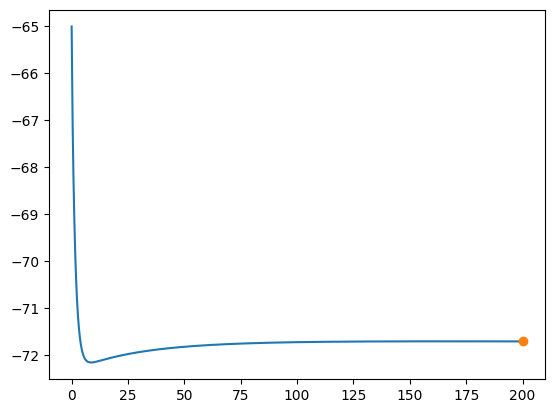

In [4]:
l2pyr= Cell(sections, cell_tree, gid=0)
l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, iascone_model_params)

soma_v = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)
t = h.Vector().record(h._ref_t)

h.celsius = 37
h.finitialize(-65 * mV)
h.continuerun(200 * ms)

RMP = soma_v[-1]
plt.plot(t, soma_v)
plt.plot(t[-1], RMP, 'o', color='tab:orange')

## Spiking measures

In [5]:
# AP threshold

ampl = np.linspace(1.5,1.4,1000)

stim = [None]*len(ampl)
voltg = [None]*len(ampl)

for i,a in enumerate(ampl):

    l2pyr= Cell(sections, cell_tree, gid=0)
    l2pyr.build()
    l2pyr = mech_class.add_mechs(l2pyr, iascone_model_params)


    stim[i] = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
    stim[i].delay = 2
    stim[i].dur = 3
    stim[i].amp = a

    l_stim = 50

    voltg[i] = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

    t = h.Vector().record(h._ref_t)

    h.celsius = 34
    h.finitialize(-65 * mV)
    h.continuerun(l_stim * ms)

    pk,_ = find_peaks(voltg[i], height=30)

    if len(pk) == 0:
        I_no_ap = [i,a]
        break



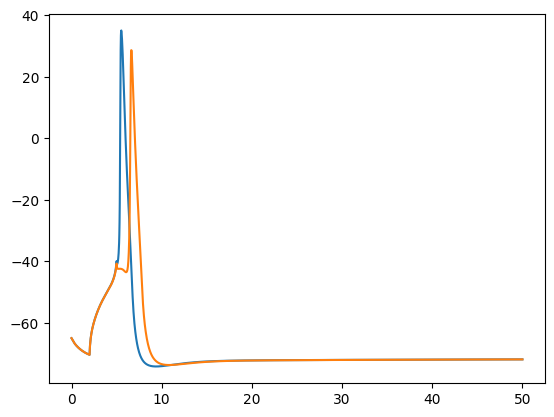

In [6]:
ampl = [1.5,I_no_ap[1]]
pk = [None]*2
stim = [None]*len(ampl)
voltg = [None]*len(ampl)

for i,a in enumerate(ampl):

    l2pyr= Cell(sections, cell_tree, gid=0)
    l2pyr.build()
    l2pyr = mech_class.add_mechs(l2pyr, iascone_model_params)


    stim[i] = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
    stim[i].delay = 2
    stim[i].dur = 3
    stim[i].amp = a

    l_stim = 50

    voltg[i] = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

    t = h.Vector().record(h._ref_t)

    h.celsius = 37
    h.finitialize(-65 * mV)
    h.continuerun(l_stim * ms)

    pk[i],_ = find_peaks(voltg[i], width=2, height=-60)


plt.plot(t, voltg[0])
plt.plot(t, voltg[1])

v_diff = voltg[0]-voltg[1]

ap_thresh = v_diff[pk[1][0]]+voltg[0][pk[1][0]]
ap_thresh

elbow_index = pk[1][0]
elbow_v = voltg[1][elbow_index]

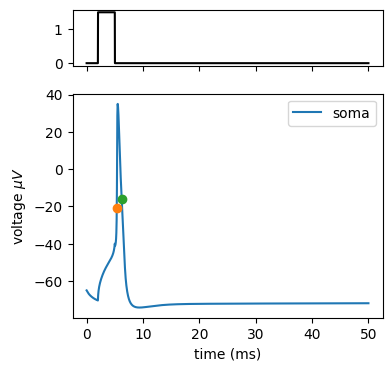

In [14]:
l2pyr= Cell(sections, cell_tree, gid=0)
l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, iascone_model_params)


stim = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
stim.delay = 2
stim.dur = 3
stim.amp = 1.5

clamp_current = h.Vector().record(stim._ref_i)


voltg = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

t = h.Vector().record(h._ref_t)

h.celsius = 37
h.finitialize(-65 * mV)
h.continuerun(l_stim * ms)

fig, ax = plt.subplots(2,1, figsize=(4,4), height_ratios=[0.25, 1], sharex=True)

ax[0].plot(t,clamp_current, color='k')

v_soma = voltg.as_numpy()
timevec = t.as_numpy()

ax[1].plot(timevec,v_soma)
ax[1].set_ylabel('voltage $\mu V$')
ax[1].set_xlabel('time (ms)')
ax[1].legend(section_names)



ap, properties = find_peaks(v_soma, width=1)


ax[1].plot(timevec[int(properties['left_ips'][1])], v_soma[int(properties['left_ips'][1])],'o', color='tab:orange')
ax[1].plot(timevec[int(properties['right_ips'][1])], v_soma[int(properties['right_ips'][1])], 'o', color='tab:green')

# upstroke

upstroke = (v_soma[ap[1]]-v_soma[int(properties['left_ips'][1])])/(timevec[ap[1]] - timevec[int(properties['left_ips'][1])])

# downstroke

downstroke = (v_soma[ap[1]]-v_soma[int(properties['right_ips'][1])])/(timevec[int(properties['right_ips'][1])]-timevec[ap[1]])

# downstroke

array([  0.  ,   0.  ,   0.  ,   0.  ,   0.  ,   4.95,   4.95,   4.95,
         4.95,   4.95,   4.95,   4.95,   4.95,   9.9 ,  14.85,  14.85,
        19.8 ,  29.7 ,  39.6 ,  44.55,  49.5 ,  54.45,  54.45,  54.45,
        54.45,  49.5 ,  49.5 ,  44.55,  34.65,  29.7 ,  29.7 ,  24.75,
        29.7 ,  24.75,  24.75,  24.75,  19.8 ,  19.8 ,  19.8 ,  19.8 ,
        19.8 ,  19.8 ,  14.85,  14.85,  14.85,  14.85,  14.85,   9.9 ,
        14.85,  14.85,   9.9 ,   9.9 ,   9.9 ,  14.85,   9.9 ,   9.9 ,
         9.9 ,  14.85,   9.9 ,   9.9 ,   9.9 ,   9.9 ,   9.9 ,   9.9 ,
         9.9 ,   9.9 ,   9.9 ,   4.95,   4.95,   9.9 ,   9.9 ,   9.9 ,
         9.9 ,   4.95,   4.95,   9.9 ,   9.9 ,   9.9 ,   9.9 ,   4.95,
         4.95,   4.95,   9.9 ,   9.9 ,   9.9 ,   4.95,   4.95, -54.45,
       -94.05])

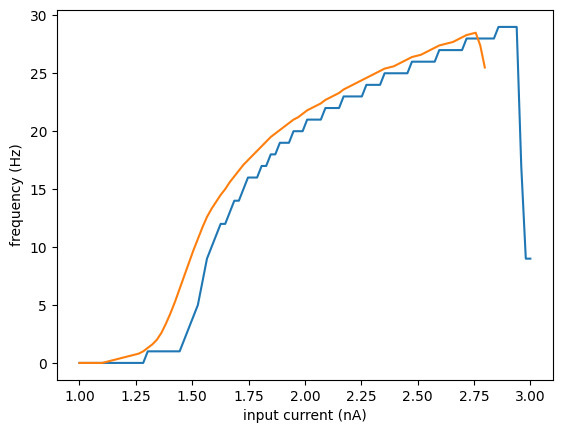

In [15]:
# FI slope
del l2pyr
ampls = np.linspace(1.,3.,100)

F = np.zeros_like(ampls)
for i,amp in enumerate(ampls):

    l2pyr= Cell(sections, cell_tree, gid=0)
    l2pyr.build()
    l2pyr = mech_class.add_mechs(l2pyr, iascone_model_params)

    stim = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
    stim.delay = 1
    stim.dur = 1000
    stim.amp = amp

    t = h.Vector().record(h._ref_t)
    soma_voltg = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

    h.celsius = 37
    h.finitialize(-65 * mV)
    h.continuerun(1001 * ms)

    soma_voltg = soma_voltg.as_numpy()

    F[i] = len(find_peaks(soma_voltg, height=0)[0])


fig, ax = plt.subplots()
ax.plot(ampls, F)
ax.set_ylabel('frequency (Hz)')
ax.set_xlabel('input current (nA)')

FI_slope = np.diff(np.array(F))/np.diff(ampls)[0]

ampl_diff = np.diff(ampls)[0]

smooth_F = np.zeros((len(F)-10,))
for i,f in enumerate(F[:-10]):
    smooth_F[i] = np.mean(F[i:i+10])

ax.plot(ampls[:-10], smooth_F)

# slope: difference in frequency per nA step
smooth_slope = np.diff(smooth_F)/np.diff(ampls[:-10])
pA = 0.001 # nA (convert nA to pA)
smooth_slope

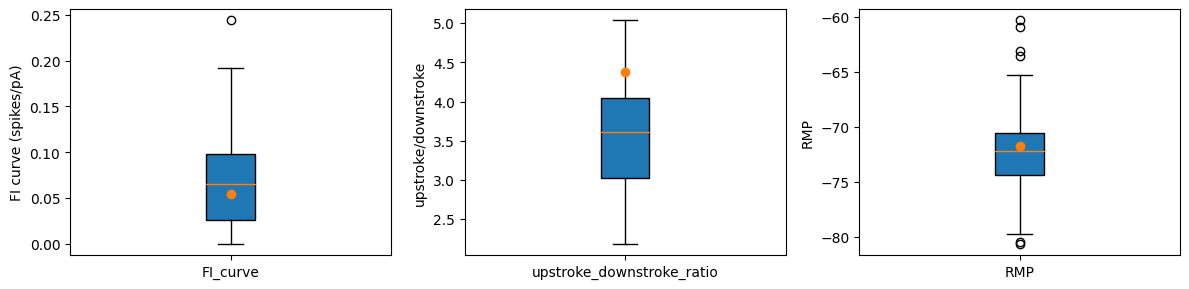

In [16]:
fig, ax = plt.subplots(1,3, figsize=(12,3))

ax = ax.ravel()
ax[0].boxplot(humanl3['ef__f_i_curve_slope'], vert=True, patch_artist=True, labels=['FI_curve'])
ax[0].set_ylabel('FI curve (spikes/pA)')
ax[0].plot(1, max(smooth_slope)*pA, 'o', color='tab:orange')

ax[1].boxplot(humanl3['ef__upstroke_downstroke_ratio_long_square'], vert=True, patch_artist=True, labels=['upstroke_downstroke_ratio'])
ax[1].set_ylabel('upstroke/downstroke')
ax[1].plot(1, upstroke/downstroke, 'o', color='tab:orange')

ax[2].boxplot(humanl3['ef__vrest'], vert=True, patch_artist=True, labels=['RMP'])
ax[2].set_ylabel('RMP')
ax[2].plot(1, RMP, 'o', color='tab:orange')

fig.tight_layout()